# Multi-View SVM (MV-SVM): instruction embeddings with a multi-kernel SVM (Jingwen Yang)

**Task.** Four-class tweet sentiment (Negative, Positive, Irrelevant, Neutral) on the group's fixed split:
473 training, 118 validation and 397 test tweets.

**Embedding model.** `intfloat/multilingual-e5-large-instruct`, an XLM-RoBERTa-large encoder (24 layers, 560M
parameters) trained for instruction-conditioned embeddings. It is kept frozen. Each tweet is encoded under six
task descriptions (sentiment, topic and style, two wordings each), which gives six 1024-dimensional views.

**Analytics model.** A multi-kernel support vector machine trained from scratch: one RBF kernel per view, the six
kernels averaged, balanced class weights. The encoder never sees a label and the SVM never changes the encoder, so
the two models are independent, as the course requires.

**Protocol.** Every choice is made by 5-fold cross-validation repeated three times on the 591-tweet training pool
(training plus validation). The test labels are read once, in the evaluation section.

## 1. Setup
Vectors are cached on disk, so a second run takes seconds. Set `JINGWEN_WORK_DIR` to move the cache.

In [1]:
import hashlib
import json
import os
import re
import shutil
import unicodedata
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
from sklearn.svm import SVC
from transformers import AutoModel, AutoTokenizer

pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU is slower but works)")

GPU: NVIDIA GeForce RTX 4090


## 2. Data
The group's cleaned rows and fixed split. The model input is the original tweet with its broken encoding repaired; case, punctuation, emoji and negations are kept, as in the other neural models of the group.

In [2]:
# paths are resolved from the notebook folder, notebooks/jingwen/
PROJECT_DIR = Path.cwd().resolve().parents[1]
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "runs" / "jingwen" / "results"            # final evaluation (committed)
EXPERIMENTS_DIR = PROJECT_DIR / "runs" / "jingwen" / "experiments"    # cross-validation logs (committed)
FIGURES_DIR = PROJECT_DIR / "reports" / "jingwen" / "figures"
# vector caches, LLM paraphrases and contrastive checkpoints (git-ignored); can be moved with JINGWEN_WORK_DIR
WORK_DIR = Path(os.environ.get("JINGWEN_WORK_DIR", PROJECT_DIR / "runs" / "jingwen" / "work"))
LABEL_NAMES = ["Negative", "Positive", "Irrelevant", "Neutral"]
LABEL_IDS = list(range(len(LABEL_NAMES)))


def normalize_text(text):
    # same light repair as the group's neural models: fix broken encoding, keep case, punctuation and emoji
    text = str(text).replace("\u00e2\u0080?", "'")
    text = ftfy.fix_text(text)
    text = re.sub(r"([A-Za-z])\s*\ufffd\s*(ve|re|ll|t|s|m|d)\b", r"\1'\2", text)
    text = unicodedata.normalize("NFC", text).replace("\ufffd", " ")
    return re.sub(r"\s+", " ", text).strip()


def load_splits():
    """Return train (473), validation (118) and test (397) frames with a `text` column."""
    pool = pd.read_csv(PROCESSED_DIR / "train_cleaned.csv", keep_default_na=False)
    test = pd.read_csv(PROCESSED_DIR / "test_cleaned.csv", keep_default_na=False)
    split = pd.read_csv(PROCESSED_DIR / "split_manifest.csv").set_index("row_id")
    pool["partition"] = pool.row_id.map(split.partition)
    if pool.partition.isna().any() or not pool.Sentiment.eq(pool.row_id.map(split.Sentiment)).all():
        raise ValueError("train_cleaned.csv and split_manifest.csv do not match")
    for frame in (pool, test):
        frame["text"] = frame.Phrase.map(normalize_text)
    train = pool[pool.partition.eq("train")].reset_index(drop=True)
    validation = pool[pool.partition.eq("validation")].reset_index(drop=True)
    return train, validation, test.reset_index(drop=True)


def text_fingerprint(texts):
    return hashlib.sha256("\n".join(texts).encode("utf-8")).hexdigest()[:16]

train, validation, test = load_splits()
print(len(train), len(validation), len(test))
display(train.Sentiment.map(dict(enumerate(LABEL_NAMES))).value_counts())

473 118 397


Sentiment
Negative      138
Positive      134
Neutral       121
Irrelevant     80
Name: count, dtype: int64

## 3. Embedding model: frozen encoders and instruction views
`ENCODERS` maps a view name to the model, the pooling and the text prefix. The six final views share one encoder and differ only in the task description.

In [3]:
# name -> (hugging face id, pooling, text prefix)
ENCODERS = {
    "mpnet": ("sentence-transformers/all-mpnet-base-v2", "mean", ""),
    "bge_large": ("BAAI/bge-large-en-v1.5", "cls", ""),
    "e5_large": ("intfloat/e5-large-v2", "mean", "query: "),
    "mxbai_large": ("mixedbread-ai/mxbai-embed-large-v1", "cls", ""),
    "bertweet": ("vinai/bertweet-base", "mean", ""),
    "twitter_roberta": ("cardiffnlp/twitter-roberta-base-sentiment-latest", "mean", ""),
    "modernbert_classification": ("nomic-ai/modernbert-embed-base", "mean", "classification: "),
    "modernbert_clustering": ("nomic-ai/modernbert-embed-base", "mean", "clustering: "),
    "gte_modernbert": ("Alibaba-NLP/gte-modernbert-base", "cls", ""),
}

# instruction-conditioned views of one instruction-tuned encoder: same tweet, different task descriptions
E5_INSTRUCT = "intfloat/multilingual-e5-large-instruct"
INSTRUCTIONS = {
    "sentiment": "Classify the sentiment of a given tweet towards the brand or game it mentions as negative, "
                 "positive, neutral, or irrelevant",
    "topic": "Identify the main topic of a given tweet",
    "emotion": "Classify the emotion expressed in the given Twitter message into one of the six emotions: "
               "anger, fear, joy, love, sadness, and surprise",
    "relevance": "Decide whether a given tweet expresses an opinion about the brand or game it mentions, "
                 "or is unrelated to it",
    "style": "Classify a given tweet as news, a personal opinion, a complaint, or casual chatter",
}
# a second wording of the three main views, to test prompt sensitivity and prompt averaging
INSTRUCTIONS_V2 = {
    "sentiment_v2": "Given a tweet that mentions a brand or a video game, classify the author's attitude toward it",
    "topic_v2": "Classify the topic of a given tweet, such as gaming, technology, business, sports, or politics",
    "style_v2": "Decide whether a given tweet is a news headline, a reposted link, or a personal post",
    "relevance_v2": "Judge whether the author of a given tweet gives a personal view of the product or game "
                    "named in it",
}
for view, instruction in (INSTRUCTIONS | INSTRUCTIONS_V2).items():
    ENCODERS[f"e5i_{view}"] = (E5_INSTRUCT, "mean", f"Instruct: {instruction}\nQuery: ")
    # the same view, mean-pooled over the last four layers instead of the last one
    ENCODERS[f"e5i_{view}_last4"] = (E5_INSTRUCT, "mean_last4", f"Instruct: {instruction}\nQuery: ")


def load_encoder(name, device="cuda"):
    model_id = ENCODERS[name][0]
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id).to(device).eval()
    return tokenizer, model


@torch.no_grad()
def encode(texts, name, tokenizer, model, batch_size=32, max_length=192, device="cuda"):
    _, pooling, prefix = ENCODERS[name]
    max_length = min(max_length, tokenizer.model_max_length, model.config.max_position_embeddings - 2)
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = [prefix + t for t in texts[start:start + batch_size]]
        inputs = tokenizer(batch, padding=True, truncation=True, max_length=max_length, return_tensors="pt").to(device)
        output = model(**inputs, output_hidden_states=pooling == "mean_last4")
        hidden = torch.stack(output.hidden_states[-4:]).mean(0) if pooling == "mean_last4" else output.last_hidden_state
        if pooling == "cls":
            pooled = hidden[:, 0]
        else:
            mask = inputs["attention_mask"].unsqueeze(-1).to(hidden.dtype)
            pooled = (hidden * mask).sum(1) / mask.sum(1)
        vectors.append(pooled.float().cpu().numpy())
    return np.concatenate(vectors)


def cached_encode(texts, name, cache_dir, tag="plain", max_length=192, **kwargs):
    """Encode `texts` with encoder `name`, reusing a cache keyed by the exact texts."""
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    spec = hashlib.sha256(repr(ENCODERS[name]).encode("utf-8")).hexdigest()[:8]
    path = cache_dir / f"{name}_{spec}_{tag}_len{max_length}_{text_fingerprint(texts)}.npy"
    if path.exists():
        return np.load(path)
    tokenizer, model = load_encoder(name)
    vectors = encode(texts, name, tokenizer, model, max_length=max_length, **kwargs)
    np.save(path, vectors)
    del model
    torch.cuda.empty_cache()
    return vectors

## 4. Analytics model: multi-kernel SVM
Each view gets an RBF kernel whose width follows sklearn's `scale` rule on the fitting rows (times 2, chosen by cross-validation); the kernels are averaged and passed to an SVM with a precomputed kernel.

In [4]:
SIX_VIEWS = ["e5i_sentiment", "e5i_topic", "e5i_style", "e5i_sentiment_v2", "e5i_topic_v2", "e5i_style_v2"]
GAMMA_SCALE = 2.0


def load_views(names, frames):
    """Encode the texts of `frames` (in order) under every view in `names`; returns {view: (rows, dim)}."""
    texts = [t for frame in frames for t in frame.text]
    return {name: cached_encode(texts, name, WORK_DIR / "cache") for name in names}


def rbf(a, b, gamma):
    sq = (a ** 2).sum(1)[:, None] + (b ** 2).sum(1)[None, :] - 2 * a @ b.T
    return np.exp(-gamma * np.maximum(sq, 0))


def fused_kernel(m, views, fit_idx, other_idx, gamma_scale=GAMMA_SCALE):
    """Average of one RBF kernel per view: (fit x fit, other x fit). Each width uses sklearn's 'scale' rule on the
    fit rows, times gamma_scale."""
    k_fit, k_other = 0, 0
    for view in views:
        a, b = normalize(m[view][fit_idx]), normalize(m[view][other_idx])
        gamma = gamma_scale / (a.shape[1] * a.var())
        k_fit = k_fit + rbf(a, a, gamma) / len(views)
        k_other = k_other + rbf(b, a, gamma) / len(views)
    return k_fit, k_other

## 5. Metrics in the group's format

In [5]:
def macro_f1(gold, predicted):
    return f1_score(gold, predicted, labels=LABEL_IDS, average="macro", zero_division=0)


def metrics(gold, predicted):
    report = classification_report(gold, predicted, labels=LABEL_IDS, target_names=LABEL_NAMES,
                                   output_dict=True, zero_division=0)
    return {"accuracy": accuracy_score(gold, predicted), "macro_f1": macro_f1(gold, predicted),
            "per_class": {name: report[name] for name in LABEL_NAMES},
            "confusion_matrix": confusion_matrix(gold, predicted, labels=LABEL_IDS).tolist()}


def per_class_table(gold, predicted, model_name):
    rows = []
    for name, scores in metrics(gold, predicted)["per_class"].items():
        rows.append({"model": model_name, "label": name, "precision": scores["precision"],
                     "recall": scores["recall"], "f1": scores["f1-score"], "support": int(scores["support"])})
    return pd.DataFrame(rows)


def paired_bootstrap(gold, treatment, control, resamples=1000, seed=2026):
    """Macro-F1 difference (treatment minus control) with a 95% paired bootstrap interval."""
    gold, treatment, control = map(np.asarray, (gold, treatment, control))
    rng = np.random.default_rng(seed)
    differences = []
    for _ in range(resamples):
        idx = rng.integers(0, len(gold), len(gold))
        differences.append(macro_f1(gold[idx], treatment[idx]) - macro_f1(gold[idx], control[idx]))
    low, high = np.percentile(differences, [2.5, 97.5])
    return {"delta_macro_f1": macro_f1(gold, treatment) - macro_f1(gold, control),
            "delta_ci_low": low, "delta_ci_high": high, "resamples": resamples}


def prediction_frame(test, predicted):
    frame = test[["row_id", "Sentiment", "cross_split_overlap"]].copy()
    frame["predicted_id"] = np.asarray(predicted)
    frame["correct"] = frame.Sentiment.eq(frame.predicted_id)
    return frame

## 6. Model selection and the single test evaluation
The ladder adds one idea at a time. For every rung, C is chosen by pooled cross-validation before any test score is computed. The final model is the six-view model; it is also refitted on all 591 labelled tweets (training plus validation, never test).

In [6]:
C_GRID = (1, 2, 4, 8, 16, 32)
LADDER = {
    "L1 bge-large + SVM": ["bge_large"],
    "L2 e5-instruct sentiment view + SVM": ["e5i_sentiment"],
    "L3 three task views + multi-kernel SVM": ["e5i_sentiment", "e5i_topic", "e5i_style"],
    "L4 six views (prompt ensemble) + multi-kernel SVM": SIX_VIEWS,
}
FINAL = "L4 six views (prompt ensemble) + multi-kernel SVM"


def choose_c(m, views, y, pool):
    cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1).split(pool, y[pool]))
    kernels = [fused_kernel(m, views, pool[a], pool[b]) for a, b in cv]
    scores = {c: np.mean([macro_f1(y[pool[b]], SVC(C=c, kernel="precomputed", class_weight="balanced")
                                   .fit(kf, y[pool[a]]).predict(ko)) for (a, b), (kf, ko) in zip(cv, kernels)])
              for c in C_GRID}
    best = max(scores, key=scores.get)
    return best, float(scores[best])


def paraphrase_flags(fit_frame, test):
    """Test tweets whose word set has Jaccard >= 0.5 with some tweet the model was fitted on (leakage found at the
    interim): measured against the 473 training rows for those models and the 591 pool rows for the refit."""
    pool_sets = [set(t.split()) for t in fit_frame.text_clean]
    flags = []
    for t in test.text_clean:
        w = set(t.split())
        flags.append(max(len(w & s) / len(w | s) for s in pool_sets) >= 0.5)
    return np.array(flags)

In [7]:
out = RESULTS_DIR
out.mkdir(parents=True, exist_ok=True)
train, validation, test = load_splits()
m = load_views(sorted({v for views in LADDER.values() for v in views}), [train, validation, test])
n_tr, n_va = len(train), len(validation)
y = np.concatenate([train.Sentiment, validation.Sentiment, np.full(len(test), -1)])
pool = np.arange(n_tr + n_va)
tr_idx, va_idx, te_idx = np.arange(n_tr), np.arange(n_tr, n_tr + n_va), np.arange(n_tr + n_va, len(y))
gold = test.Sentiment.to_numpy()
leak = {473: paraphrase_flags(train, test), 591: paraphrase_flags(pd.concat([train, validation]), test)}

tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                      LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=7))
predictions = {"L0 TF-IDF + LR (shared baseline)": tfidf.fit(train.text_clean, train.Sentiment).predict(test.text_clean)}
val_scores = {"L0 TF-IDF + LR (shared baseline)": macro_f1(validation.Sentiment, tfidf.predict(validation.text_clean))}
chosen = {}
for name, views in LADDER.items():
    c, cv_score = choose_c(m, views, y, pool)
    chosen[name] = {"views": views, "C": c, "pool_cv_macro_f1": cv_score}
    kf, kv = fused_kernel(m, views, tr_idx, va_idx)
    _, kt = fused_kernel(m, views, tr_idx, te_idx)
    model = SVC(C=c, kernel="precomputed", class_weight="balanced").fit(kf, y[tr_idx])
    val_scores[name] = macro_f1(y[va_idx], model.predict(kv))
    predictions[name] = model.predict(kt)
views, c = LADDER[FINAL], chosen[FINAL]["C"]
kf, kt = fused_kernel(m, views, pool, te_idx)
predictions["L4 refit on all 591 rows"] = SVC(C=c, kernel="precomputed", class_weight="balanced").fit(kf, y[pool]).predict(kt)
base_591 = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000, random_state=7))
predictions["L0 TF-IDF + LR, 591 rows"] = base_591.fit(pd.concat([train, validation]).text_clean,
                                                       y[pool]).predict(test.text_clean)

rows, per_class, boot = [], [], []
for name, pred in predictions.items():
    n_fit = len(pool) if "591" in name else n_tr
    full, clean = metrics(gold, pred), metrics(gold[~leak[n_fit]], pred[~leak[n_fit]])
    rows.append({"model": name, "train_n": n_fit,
                 "val_macro_f1": val_scores.get(name), "test_accuracy": full["accuracy"],
                 "test_macro_f1": full["macro_f1"], "test_macro_f1_without_paraphrases": clean["macro_f1"],
                 **{f"{lab}_f1": full["per_class"][lab]["f1-score"] for lab in LABEL_NAMES}})
    per_class.append(per_class_table(gold, pred, name))
    key = name.split()[0] + ("_591" if "591" in name else "")
    (out / f"confusion_{key}.json").write_text(json.dumps(full["confusion_matrix"]))
    control = "L0 TF-IDF + LR, 591 rows" if "591" in name else "L0 TF-IDF + LR (shared baseline)"
    if not name.startswith("L0"):
        boot.append({"treatment": name, "control": control, **paired_bootstrap(gold, pred, predictions[control])})
boot.append({"treatment": FINAL, "control": "L1 bge-large + SVM",
             **paired_bootstrap(gold, predictions[FINAL], predictions["L1 bge-large + SVM"])})
pd.DataFrame(rows).to_csv(out / "comparison.csv", index=False)
pd.concat(per_class).to_csv(out / "per_class_metrics.csv", index=False)
pd.DataFrame(boot).to_csv(out / "paired_bootstrap.csv", index=False)
prediction_frame(test, predictions[FINAL]).assign(paraphrase_in_train=leak[n_tr]).to_csv(out / "test_predictions.csv", index=False)
prediction_frame(test, predictions["L4 refit on all 591 rows"]).assign(paraphrase_in_pool=leak[len(pool)]).to_csv(
    out / "test_predictions_refit591.csv", index=False)
pd.DataFrame({"row_id": test.row_id, "Sentiment": gold} | {k: v for k, v in predictions.items()}).to_csv(
    out / "all_test_predictions.csv", index=False)
shutil.copy(PROCESSED_DIR / "split_manifest.csv", out / "split_manifest.csv")
(out / "chosen_settings.json").write_text(json.dumps(chosen | {"gamma_scale": 2.0,
                                                               "paraphrased_test_rows_vs_473": int(leak[n_tr].sum()),
                                                               "paraphrased_test_rows_vs_591": int(leak[len(pool)].sum())},
                                                indent=2))
with pd.option_context("display.width", 250, "display.max_columns", 20, "display.precision", 4):
    print(pd.DataFrame(rows).drop(columns=["train_n"]))
    print(pd.DataFrame(boot)[["treatment", "control", "delta_macro_f1", "delta_ci_low", "delta_ci_high"]])
print("paraphrased test rows vs 473 / 591:", int(leak[n_tr].sum()), int(leak[len(pool)].sum()))


## 7. Figures

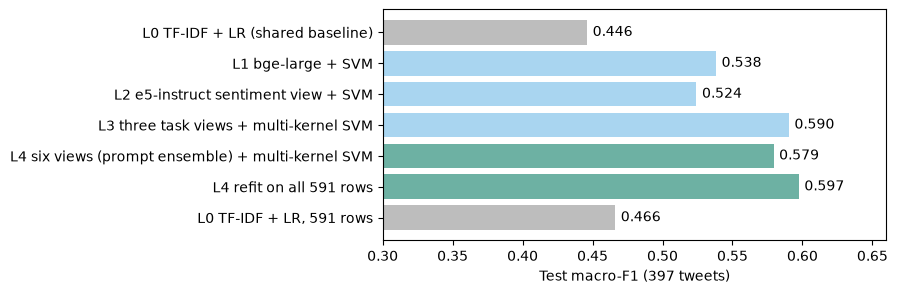

label,Negative,Positive,Irrelevant,Neutral
model,,,,
L0 TF-IDF + LR (shared baseline),0.5887,0.4279,0.2564,0.5114
"L0 TF-IDF + LR, 591 rows",0.6159,0.4465,0.3023,0.5000
L1 bge-large + SVM,0.6963,0.5797,0.3455,0.5314
L2 e5-instruct sentiment view + SVM,0.6970,0.5648,0.2946,0.5405
L3 three task views + multi-kernel SVM,0.7063,0.6346,0.4276,0.5926
L4 refit on all 591 rows,0.7023,0.6540,0.4186,0.6146
L4 six views (prompt ensemble) + multi-kernel SVM,0.6970,0.6436,0.3582,0.6186


In [8]:
results = pd.read_csv(RESULTS_DIR / "comparison.csv")
fig, ax = plt.subplots(figsize=(6.5, 3))
order = results.model.tolist()
ax.barh(order[::-1], results.test_macro_f1[::-1], color=["#6DB1A3" if m.startswith("L4") else "#BDBDBD" if m.startswith("L0") else "#A9D5F0" for m in order[::-1]])
for i, v in enumerate(results.test_macro_f1[::-1]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center")
ax.set_xlim(0.3, 0.66)
ax.set_xlabel("Test macro-F1 (397 tweets)")
plt.show()

per = pd.read_csv(RESULTS_DIR / "per_class_metrics.csv")
display(per.pivot(index="model", columns="label", values="f1")[LABEL_NAMES])

The report figures (paper style, PDF and PNG) are produced by `figures.py` into `reports/jingwen/figures/`.

## 8. Experiment log
Every idea tried during development, with its pooled cross-validation macro-F1 (591 tweets, 5-fold x 3). The scripts are in `models/jingwen/experiments/`; their logs are read here, not rerun.

In [9]:
log = EXPERIMENTS_DIR
pool = {**json.loads((log / "pool_cv.json").read_text()), **json.loads((log / "pool_cv_r2.json").read_text())}
tune = json.loads((log / "tune.json").read_text())
rows = [("bge-large, frozen", pool["bge"]["pool_cv_mean"], "single encoder"),
        ("e5-large, frozen", pool["e5"]["pool_cv_mean"], "single encoder"),
        ("+ entity-masked view", pool["bge+masked"]["pool_cv_mean"], "not adopted"),
        ("one instruction view", pool["e5i_sentiment"]["pool_cv_mean"], "single view"),
        ("sentiment + topic views", pool["e5i_sent+topic"]["pool_cv_mean"], "adopted"),
        ("sentiment + topic + style views", pool["sent+topic+style"]["pool_cv_mean"], "adopted"),
        ("concatenation instead of kernel sum", tune["A_fusion"]["concatenation, one RBF"]["mean"], "not adopted"),
        ("kernel product", tune["A_fusion"]["product of view kernels"]["mean"], "not adopted"),
        ("linear kernel", tune["E_kernel"]["linear"]["mean"], "not adopted"),
        ("+ general encoder view", tune["C_extra"]["+bge_large weight 1"]["mean"], "not adopted"),
        ("+ last-4-layer pooling", json.loads((log / "round1.json").read_text())["six, last-4 layers"]["mean"], "not adopted"),
        ("+ label-noise filter (10%)", json.loads((log / "noise.json").read_text())["0.1"]["mean"], "not adopted"),
        ("+ LLM paraphrases (1 copy)", json.loads((log / "aug_cv.json").read_text())["copies=1 weight=1.0"]["mean"], "not adopted (gain in only half of the folds)"),
        ("six views, prompt ensemble (final)", tune["D_wording"]["v1 and v2 kernels averaged"]["mean"], "final")]
display(pd.DataFrame(rows, columns=["idea", "pooled CV macro-F1", "decision"]))
families = json.loads((log / "families.json").read_text())
display(pd.DataFrame([(k, v["mean"], v["setting"]) for k, v in families.items()],
                     columns=["classifier on the same six views", "pooled CV macro-F1", "best setting"]))
# class weights against no weights over the C grid (six views), with the effect on the Irrelevant class
weights = pd.DataFrame(json.loads((log / "imbalance.json").read_text()))
display(weights[["class_weight", "C", "macro_f1", "Irrelevant_recall", "Irrelevant_f1", "Positive_recall"]])

,idea,pooled CV macro-F1,decision
0,"bge-large, frozen",0.5152,single encoder
1,"e5-large, frozen",0.5296,single encoder
2,+ entity-masked view,0.5079,not adopted
3,one instruction view,0.5275,single view
4,sentiment + topic views,0.5470,adopted
5,sentiment + topic + style views,0.5568,adopted
6,concatenation instead of kernel sum,0.5575,not adopted
7,kernel product,0.5581,not adopted
8,linear kernel,0.5494,not adopted
9,+ general encoder view,0.5504,not adopted


,classifier on the same six views,pooled CV macro-F1,best setting
0,kNN (cosine),0.5120,k=5
1,Random forest,0.5408,trees=500 depth=12
2,Gradient boosting (PCA 64),0.5189,lr=0.1
3,Gaussian process (PCA 128),0.4714,length=1.0
4,MLP,0.5523,hidden=512 alpha=0.01 epochs=50


,class_weight,C,macro_f1,Irrelevant_recall,Irrelevant_f1,Positive_recall
0,balanced,1,0.5166,0.2993,0.3199,0.5879
1,balanced,2,0.5523,0.3522,0.3804,0.6141
2,balanced,4,0.5645,0.3835,0.4049,0.6283
3,balanced,8,0.5597,0.3678,0.3840,0.6263
4,balanced,16,0.5521,0.3496,0.3704,0.6242
5,balanced,32,0.5441,0.3242,0.3524,0.6384
6,none,1,0.4495,0.0063,0.0121,0.7172
7,none,2,0.4982,0.1196,0.1781,0.6848
8,none,4,0.5409,0.2203,0.3034,0.6808
9,none,8,0.5613,0.2769,0.3447,0.6788


## 9. Error analysis
Tweets the baseline got wrong and the final model got right, the most common remaining confusions, and training tweets whose label disagrees most with out-of-fold predictions (likely label noise).

In [10]:
preds = pd.read_csv(RESULTS_DIR / "all_test_predictions.csv").merge(test[["row_id", "text"]], on="row_id")
base, final = "L0 TF-IDF + LR (shared baseline)", "L4 six views (prompt ensemble) + multi-kernel SVM"
name = dict(enumerate(LABEL_NAMES))
fixed = preds[(preds[base] != preds.Sentiment) & (preds[final] == preds.Sentiment)]
print(f"fixed by the final model: {len(fixed)} tweets; broken by it: "
      f"{int(((preds[base] == preds.Sentiment) & (preds[final] != preds.Sentiment)).sum())}")
display(fixed.assign(label=fixed.Sentiment.map(name), baseline=fixed[base].map(name))[["row_id", "label", "baseline"]].head(8))
wrong = preds[preds[final] != preds.Sentiment]
display(pd.crosstab(wrong.Sentiment.map(name), wrong[final].map(name)).rename_axis(index="true", columns="predicted"))
display(pd.read_csv(EXPERIMENTS_DIR / "suspect_labels.csv").assign(label=lambda f: f.Sentiment.map(name))[["row_id", "label", "margin"]].head(8))

fixed by the final model: 81 tweets; broken by it: 35


predicted,Irrelevant,Negative,Neutral,Positive
true,,,,
Irrelevant,0,19,9,14
Negative,9,0,9,10
Neutral,17,21,0,7
Positive,18,12,11,0


## 10. Baseline refinement: B0 to B1
B1 keeps TF-IDF + logistic regression and tunes the input text, the n-grams, the minimum document frequency, C and the class weights with the same repeated 5-fold x 3 CV on the 591 labelled tweets (320 configurations). The search is `models/jingwen/baseline_b1.py`; its outputs are read here, not rerun.

In [11]:
b1 = RESULTS_DIR.parent / "b1"
print(json.loads((b1 / "chosen.json").read_text()))
display(pd.read_csv(b1 / "cv_grid.csv").head(10))
display(pd.read_csv(b1 / "test_comparison.csv"))
display(pd.read_csv(b1 / "paired_bootstrap.csv"))

{'B1': {'input': 'text', 'features': 'char 2-5', 'min_df': 1, 'C': 2.0, 'class_weight': 'balanced'}, 'B1_cv_macro_f1': 0.44984784218175355, 'B1_cv_std': 0.02772145353701929, 'B0_cv_macro_f1': 0.400112855077078, 'B0_cv_std': 0.041816374343405883, 'configurations': 320}


,input,features,min_df,C,class_weight,cv_macro_f1,cv_std
0,text,char 2-5,1,2.00,balanced,0.4498,0.0277
1,text,char 2-5,1,1.00,balanced,0.4494,0.0235
2,text,word 1-2 + char 2-5,1,0.50,balanced,0.4469,0.0310
3,text,word 1-2 + char 2-5,1,0.25,balanced,0.4468,0.0295
4,text,word 1-2 + char 2-5,1,1.00,balanced,0.4460,0.0343
5,text,char 2-5,1,0.50,balanced,0.4451,0.0222
6,text_clean,word 1-2,1,0.50,balanced,0.4445,0.0387
7,text_clean,word 1-2,1,32.00,balanced,0.4437,0.0379
8,text_clean,word 1-2 + char 2-5,1,1.00,balanced,0.4434,0.0455
9,text_clean,word 1-2,1,4.00,balanced,0.4434,0.0432


,model,train_n,accuracy,macro_precision,macro_recall,macro_f1,macro_f1_without_paraphrases,irrelevant_recall
0,B0,591,0.5063,0.5330,0.4693,0.4662,0.4286,0.1970
1,B0,473,0.4912,0.5647,0.4526,0.4461,0.4165,0.1515
2,B1,591,0.5315,0.5191,0.5129,0.5122,0.4808,0.3939
3,B1,473,0.5013,0.4942,0.4788,0.4808,0.4486,0.3182


,train_n,delta_macro_f1,delta_ci_low,delta_ci_high,resamples
0,591,0.0460,-0.0074,0.1007,1000
1,473,0.0347,-0.0189,0.0866,1000
